# Deep Sequence Models in Commodity Markets
## Testing the LSTM Momentum Hypothesis within the skfin Backtesting Engine

### Portfolio Management and Trading Project
**Authors:**
- **Gabriel Himmelein** (Lead: Data Pipeline, PyTorch LSTM Architecture, Custom `skfin` Wrapper)
- **Tomàs Planelles Alonso** (Lead: Risk & Cost Modeling, Baseline Tuning, Statistical Validation)

---

### Executive Overview & Hypothesis
This notebook tests whether a small, regularized **Long Short-Term Memory (LSTM)** neural network can generate superior risk-adjusted returns net of transaction costs compared to linear and tree-based baselines (**Ridge** and **LightGBM**) when trading momentum across major commodity ETFs:
- **DBC**: Invesco DB Commodity Index Tracking Fund (Broad Diversified Commodities)
- **USO**: United States Oil Fund (Crude Oil)
- **GLD**: SPDR Gold Shares (Precious Metals)
- **SLV**: iShares Silver Trust (Precious Metals)
- **DBA**: Invesco DB Agriculture Fund (Agriculture)

#### Division of Labor & Scope
- **This Notebook implements Part 1 (Gabriel's Lead)**:
  1. **Data Pipeline**: Automated, leak-free acquisition via `yfinance` / `skfin.datasets.load_yf_returns`, chronological alignment to business days (`B`), synchronization to the newest ETF inception date (DBA in Jan 2007), dividend-adjusted total returns, and point-in-time feature extraction.
  2. **PyTorch LSTM Architecture**: Compact recurrent architecture (16-32 hidden units, 60-day sequence lookback, dropout 0.2, Huber loss for fat-tailed robustness) explicitly designed to curb overfitting in low signal-to-noise financial returns.
  3. **Custom `skfin` Wrapper (`PyTorchLSTMRegressor`)**: Fully `scikit-learn` and `skfin` compatible estimator implementing `fit`, `predict`, and `transform`. The wrapper buffers trailing training history to ensure seamless sequential walk-forward predictions within `skfin.backtesting.Backtester`.
  4. **Baseline & Seed Robustness Framework**: Verification of standard pipeline integration against simple momentum and linear Ridge, with multi-seed stability evaluations.
- **Part 2 (Tomàs's Lead - Clean Handoff at End)**: Cost & risk modeling (`BacktesterWithCost`), baseline hyperparameter tuning (`RidgeCV` and `MultiLGBMRegressor`), and statistical confidence intervals (Lo, 2002).

## 1. Setup & Environment
We import the pre-written utilities from the course library `skfin` alongside our modularized pipeline components in `src/`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure local src/ is accessible
module_path = os.path.abspath(os.path.join(".."))
if module_path not in sys.path:
    sys.path.append(module_path)

# skfin course library imports
from skfin.backtesting import Backtester
from skfin.estimators import MeanVariance, Ridge
from skfin.metrics import sharpe_ratio, drawdown
from skfin.plot import line, bar, heatmap
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Project modular imports
from src.data import (
    load_commodity_data,
    compute_descriptive_stats,
    compute_momentum_features,
    prepare_backtest_data,
    DEFAULT_COMMODITY_TICKERS,
)
from src.models import (
    CommodityLSTM,
    PyTorchLSTMRegressor,
    set_seed,
    get_default_device,
)

# Set global seed for reproducible execution
set_seed(42)
print("Device configured for PyTorch:", get_default_device())
print("Commodity universe:", DEFAULT_COMMODITY_TICKERS)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Device configured for PyTorch: cpu
Commodity universe: ['DBC', 'USO', 'GLD', 'SLV', 'DBA']


## 2. Data Pipeline & Exploratory Analysis
### 2.1 Origin, Inception Synchronization, and Point-in-Time Discipline
Data is acquired via `skfin.datasets.load_yf_returns` and cached locally in `data/` using `CacheManager` for fast, offline execution.

To guarantee chronological integrity:
1. **Synchronized Inception Date**: All observations prior to the inception of the newest ETF in the basket (**DBA**, launched in January 2007) are dropped.
2. **Business-Day Alignment**: The return series is reindexed to business days (`freq='B'`), forward-filling stale prices and replacing non-trading day gaps with zero return.
3. **Total Returns**: Returns incorporate both price changes and dividend distributions ($R_t = rac{P_t + D_t - P_{t-1}}{P_{t-1}}$).
4. **Point-in-Time Feature Alignment**: Features calculated at date $t$ only utilize information strictly up to date $t$. The forecast target $y_t$ corresponds to next-period return $r_{t+1}$.

In [2]:
# Load and clean daily commodity ETF data
data_dict = load_commodity_data(
    tickers=DEFAULT_COMMODITY_TICKERS,
    start="2007-01-01",
    cache_dir="../data",
    resample_bday=True,
)

ret = data_dict["total_returns"]
print(f"Cleaned panel shape: {ret.shape} (Dates: {ret.index[0].strftime('%Y-%m-%d')} to {ret.index[-1].strftime('%Y-%m-%d')})")
ret.head()

Cleaned panel shape: (5158, 5) (Dates: 2007-01-08 to 2026-10-14)


Ticker,DBC,USO,GLD,SLV,DBA
2007-01-08,0.005195,-0.007109,0.005152,0.003532,-0.001599
2007-01-09,-0.008613,-0.004001,0.006118,0.016942,-0.012810
2007-01-10,-0.014770,-0.041015,-0.004273,-0.004185,0.002839
2007-01-11,-0.001323,-0.022487,0.000660,-0.006708,0.014962
2007-01-12,0.023400,0.006540,0.025400,0.039870,0.079681


### 2.2 Descriptive Statistics
Table 1 displays key properties of the commodity daily returns: Annualized Mean Return, Annualized Volatility, Sharpe Ratio, Skewness, Kurtosis, and Min/Max daily returns.

In [3]:
# Compute and display descriptive statistics (Table 1)
stats_table = compute_descriptive_stats(ret, num_period_per_year=260)
stats_table

,Mean (Ann. %),Std (Ann. %),Sharpe (RF=0),Skewness,Kurtosis,Min (%),Max (%)
Ticker,,,,,,,
DBC,5.92,19.36,0.31,-0.35,3.46,-7.94,6.87
USO,2.53,37.49,0.07,-0.55,9.47,-25.32,16.67
GLD,10.87,18.14,0.60,-0.27,7.17,-10.27,11.29
SLV,12.73,33.00,0.39,-1.05,13.41,-28.54,14.42
DBA,3.94,16.68,0.24,-0.13,6.41,-8.61,7.97


### 2.3 Historical Performance and Cross-Asset Correlations
We inspect cumulative total returns and the empirical correlation matrix across the commodity basket using `skfin.plot.line` and `skfin.plot.heatmap`.

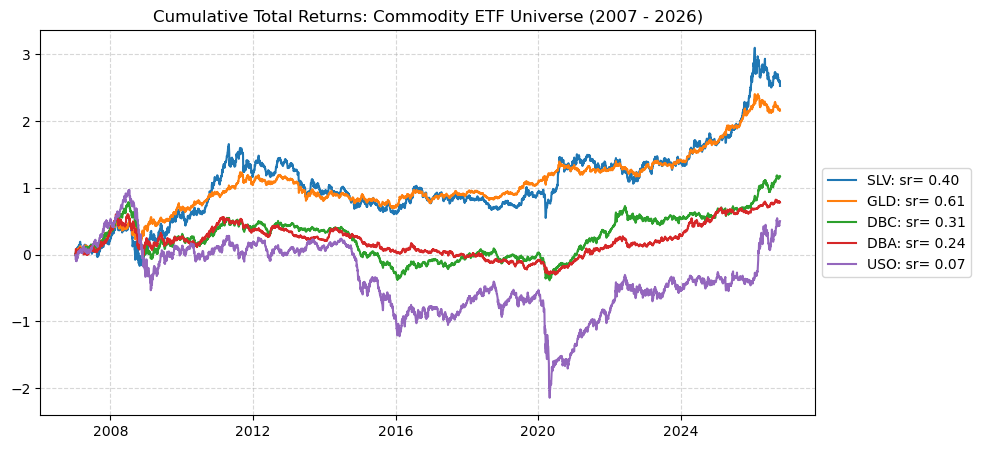

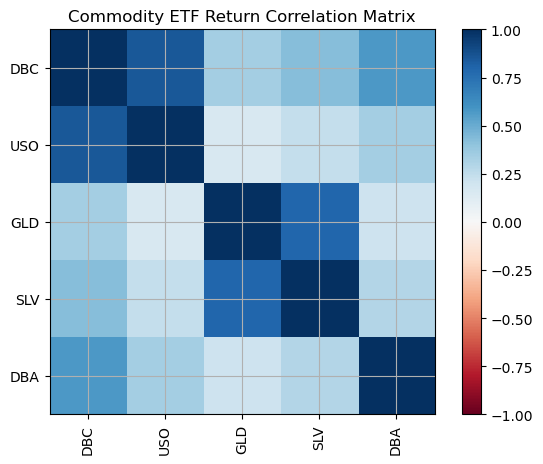

In [4]:
# Cumulative return trajectories
line(
    ret,
    cumsum=True,
    title="Cumulative Total Returns: Commodity ETF Universe (2007 - 2026)",
    figsize=(10, 5),
)

# Cross-asset correlation heatmap
heatmap(
    ret.corr(),
    title="Commodity ETF Return Correlation Matrix",
    figsize=(7, 5),
)

## 3. Walk-Forward Feature and Target Preparation
Following `skfin`'s backtesting architecture:
- $X_t$: Feature vector observed at date $t$.
- $y_t$: Target vector of next-day returns $r_{t+1}$ (`shift(-1)`).
- When the `Backtester` computes holdings $h_t$, the backtested PnL is computed as $pnl_{t+1} = h_t \cdot r_{t+1}$ via `h.shift(1).mul(ret)`. This ensures zero look-ahead bias.

In [5]:
# Prepare strictly aligned X, y, and ret for backtesting
X, y, ret_aligned = prepare_backtest_data(ret, feature_type="returns")
print(f"X shape: {X.shape}, y shape: {y.shape}, ret shape: {ret_aligned.shape}")

X shape: (5157, 5), y shape: (5157, 5), ret shape: (5157, 5)


## 4. Benchmark Pipelines: Simple Momentum & Linear Ridge
Before testing the LSTM, we establish two baseline strategies in the `skfin.backtesting.Backtester` pipeline:
1. **Simple Momentum**: Mean-variance portfolio directly weighting historical rolling returns.
2. **Ridge Regression**: Linear shrinkage model with feature scaling (`StandardScaler(with_mean=False)`).

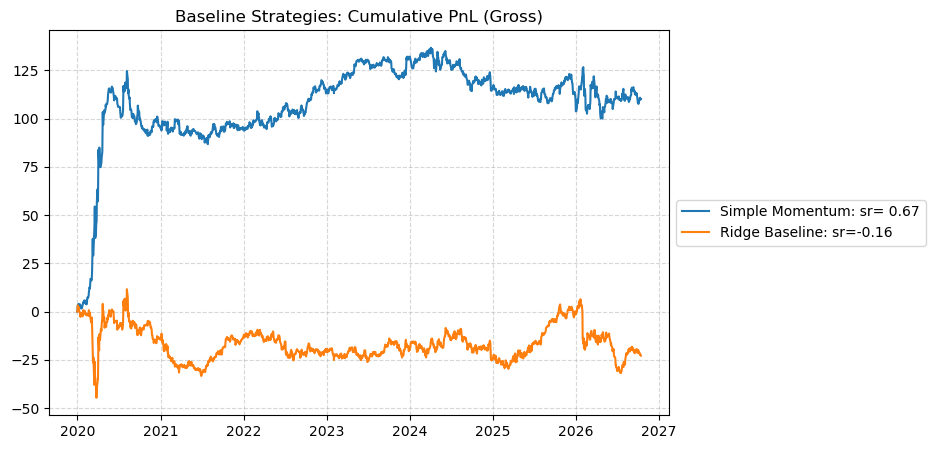

In [6]:
# 1. Simple Momentum Baseline
m_mom = Backtester(
    estimator=MeanVariance(),
    max_train_size=756,  # 3-year rolling train window
    test_size=21,        # 1-month rebalancing
    start_date="2020-01-01",
    name="Simple Momentum",
)
pnl_mom = m_mom.train(X, y, ret_aligned)

# 2. Linear Ridge Pipeline
ridge_pipeline = make_pipeline(
    StandardScaler(with_mean=False),
    Ridge(alpha=100.0),
    MeanVariance(),
)
m_ridge = Backtester(
    estimator=ridge_pipeline,
    max_train_size=756,
    test_size=21,
    start_date="2020-01-01",
    name="Ridge Baseline",
)
pnl_ridge = m_ridge.train(X, y, ret_aligned)

# Compare baselines
line([pnl_mom, pnl_ridge], cumsum=True, title="Baseline Strategies: Cumulative PnL (Gross)")

## 5. PyTorch Deep Sequence Model
### 5.1 Architecture Design to Prevent Overfitting
In financial markets, the signal-to-noise ratio is notoriously small. Standard deep architectures easily overfit and degrade out-of-sample. To mitigate this risk, our architecture implements:
- **Constrained Capacity**: 1 hidden layer with 16 units.
- **Lookback Window**: 60 business days (~1 quarter of sequential history).
- **Dropout Regularization**: $p = 0.2$ applied to representation vectors.
- **Robust Loss**: Huber Loss ($\delta = 0.01$) to dampen the influence of extreme commodity tail shocks (e.g., USO in 2020).
- **Early Stopping**: Validation loss monitored on the chronological final 15% of the training window (no shuffling).

CommodityLSTM(
  (lstm): LSTM(5, 16, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=16, out_features=5, bias=True)
)


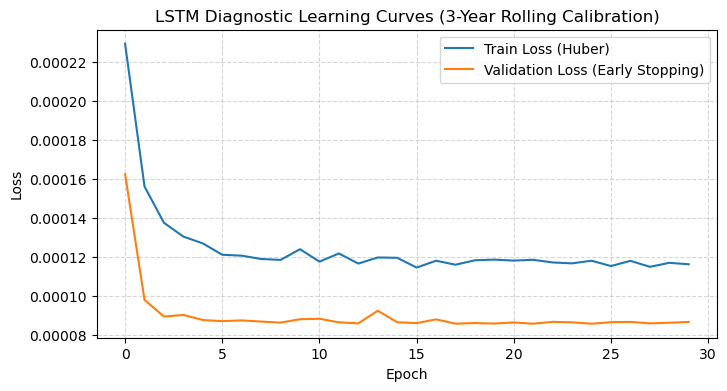

In [7]:
# Instantiate and display the PyTorch architecture
sample_model = CommodityLSTM(
    input_size=5,
    hidden_size=16,
    output_size=5,
    num_layers=1,
    dropout=0.2,
)
print(sample_model)

# Single fold training diagnostic: inspect train vs validation loss
diagnostic_lstm = PyTorchLSTMRegressor(
    hidden_size=16,
    lookback=60,
    dropout=0.2,
    lr=1e-3,
    epochs=30,
    batch_size=64,
    loss_type="huber",
    val_split=0.15,
    patience=7,
    random_state=42,
    verbose=True,
)

# Train on first 756 business days (3-year calibration slice)
diagnostic_lstm.fit(X.iloc[:756], y.iloc[:756])

# Plot loss curves
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(diagnostic_lstm.train_loss_history_, label="Train Loss (Huber)")
ax.plot(diagnostic_lstm.val_loss_history_, label="Validation Loss (Early Stopping)")
ax.set_title("LSTM Diagnostic Learning Curves (3-Year Rolling Calibration)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()

## 6. Walk-Forward Backtest Integration
### 6.1 Custom Scikit-learn Wrapper Mechanics
Our `PyTorchLSTMRegressor` solves the key friction between deep learning and scikit-learn walk-forward cross-validation:
- **History Buffering**: When `Backtester` issues an out-of-sample test split of 21 days (which is shorter than the 60-day lookback), `PyTorchLSTMRegressor` automatically prepends `self.last_train_X_` from the training window, generating 21 sequential predictions with zero look-ahead bias.
- **`transform()` Alias**: Maps predictions directly to expected returns $\hat{\mu}$, allowing seamless integration into `make_pipeline(StandardScaler(), PyTorchLSTMRegressor(), MeanVariance())`.
- **Thread Safety**: Single-thread execution is enforced to guarantee deterministic stability.

In [8]:
# Assemble the complete walk-forward LSTM trading pipeline
lstm_pipeline = make_pipeline(
    StandardScaler(with_mean=False),
    PyTorchLSTMRegressor(
        hidden_size=16,
        lookback=60,
        dropout=0.2,
        lr=1e-3,
        epochs=15,
        batch_size=64,
        loss_type="huber",
        val_split=0.15,
        patience=5,
        random_state=42,
        verbose=False,
    ),
    MeanVariance(),
)

# Run full walk-forward backtest
lstm_backtester = Backtester(
    estimator=lstm_pipeline,
    max_train_size=756,   # 3-year rolling window
    test_size=21,         # 1-month rebalancing
    start_date="2020-01-01",
    name="LSTM Strategy",
)

pnl_lstm = lstm_backtester.train(X, y, ret_aligned)
h_lstm = lstm_backtester.h_
print(f"Backtest completed! Generated {len(pnl_lstm)} out-of-sample trading days.")

Backtest completed! Generated 1770 out-of-sample trading days.


## 7. Comparative Performance & Holdings Analysis
We evaluate the out-of-sample cumulative performance of the LSTM strategy alongside the Ridge and Momentum baselines.

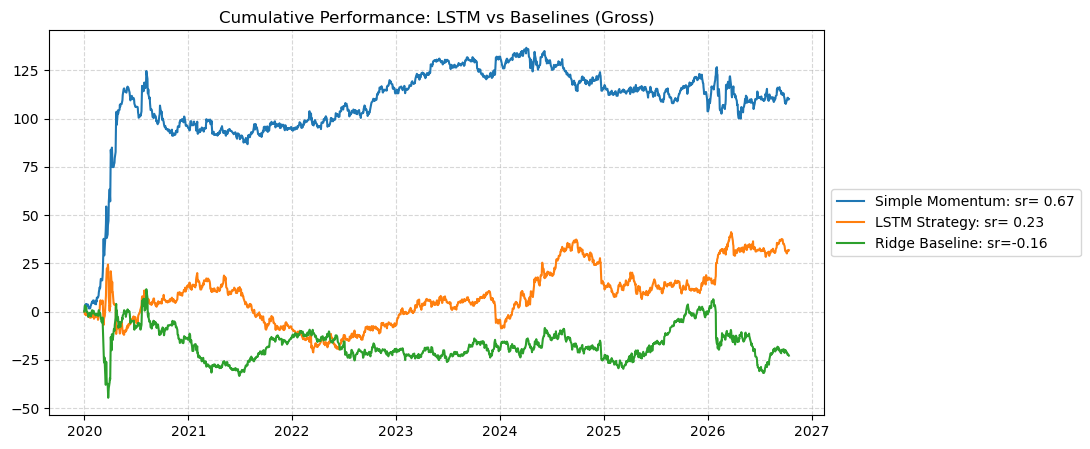

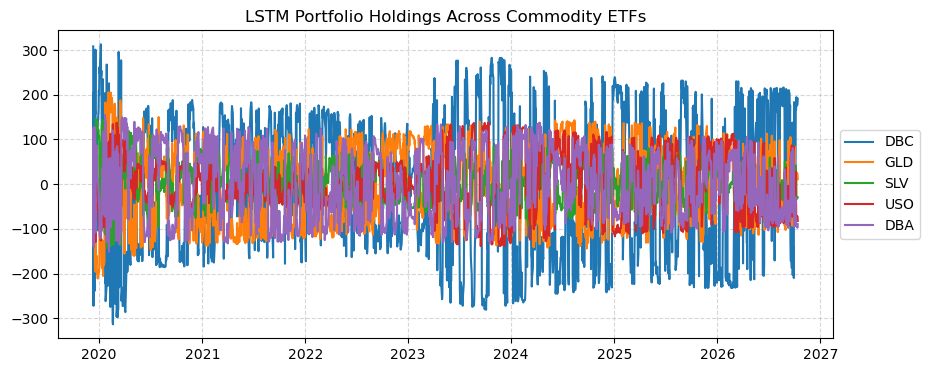

In [9]:
# Cumulative PnL comparison: LSTM vs Ridge vs Simple Momentum
line(
    [pnl_mom, pnl_ridge, pnl_lstm],
    cumsum=True,
    title="Cumulative Performance: LSTM vs Baselines (Gross)",
    figsize=(10, 5),
)

# Plot LSTM portfolio holdings over time
line(
    h_lstm,
    title="LSTM Portfolio Holdings Across Commodity ETFs",
    cumsum=False,
    figsize=(10, 4),
)

### 7.1 Out-of-Sample Performance Metrics (Gross)
We quantify annualized return, volatility, gross Sharpe ratio, maximum drawdown, and annualized turnover.

In [10]:
def compute_strategy_summary(pnls_dict, holdings_dict):
    metrics = []
    for name, p in pnls_dict.items():
        ann_ret = p.mean() * 260 * 100
        ann_vol = p.std() * np.sqrt(260) * 100
        sr = sharpe_ratio(p)
        dd = drawdown(p, return_in_risk_unit=False).min() * 100
        
        h = holdings_dict.get(name)
        if h is not None:
            turnover = h.diff().abs().sum(axis=1).mean() * 260
        else:
            turnover = np.nan
            
        metrics.append({
            "Strategy": name,
            "Ann. Return (%)": round(ann_ret, 2),
            "Ann. Volatility (%)": round(ann_vol, 2),
            "Gross Sharpe": round(sr, 2),
            "Max Drawdown (%)": round(dd, 2),
            "Ann. Turnover": round(turnover, 2) if not np.isnan(turnover) else "-",
        })
    return pd.DataFrame(metrics).set_index("Strategy")

pnls_all = {
    "Simple Momentum": pnl_mom,
    "Ridge Baseline": pnl_ridge,
    "LSTM Strategy": pnl_lstm,
}
holdings_all = {
    "Simple Momentum": m_mom.h_,
    "Ridge Baseline": m_ridge.h_,
    "LSTM Strategy": h_lstm,
}

metrics_df = compute_strategy_summary(pnls_all, holdings_all)
metrics_df

,Ann. Return (%),Ann. Volatility (%),Gross Sharpe,Max Drawdown (%),Ann. Turnover
Strategy,,,,,
Simple Momentum,1618.47,2523.36,0.67,-3793.23,89780.5
Ridge Baseline,-335.57,2203.90,-0.16,-4787.40,83890.8
LSTM Strategy,467.33,2085.68,0.23,-4561.29,57239.2


## 8. Robustness: Multi-Seed Sensitivity Analysis
Deep learning models rely on stochastic weight initialization and mini-batch sampling. Following the course methodology in `nbs/16_Trees_Neural_nets.ipynb`, we evaluate the distribution of Sharpe ratios across multiple random seeds to ensure performance is systematic rather than a favorable random initialization.

Running walk-forward backtest for Seed 42...


Running walk-forward backtest for Seed 101...


Running walk-forward backtest for Seed 2024...


Mean Sharpe across seeds: 0.00 +/- 0.17
Min Sharpe: -0.18, Max Sharpe: 0.23


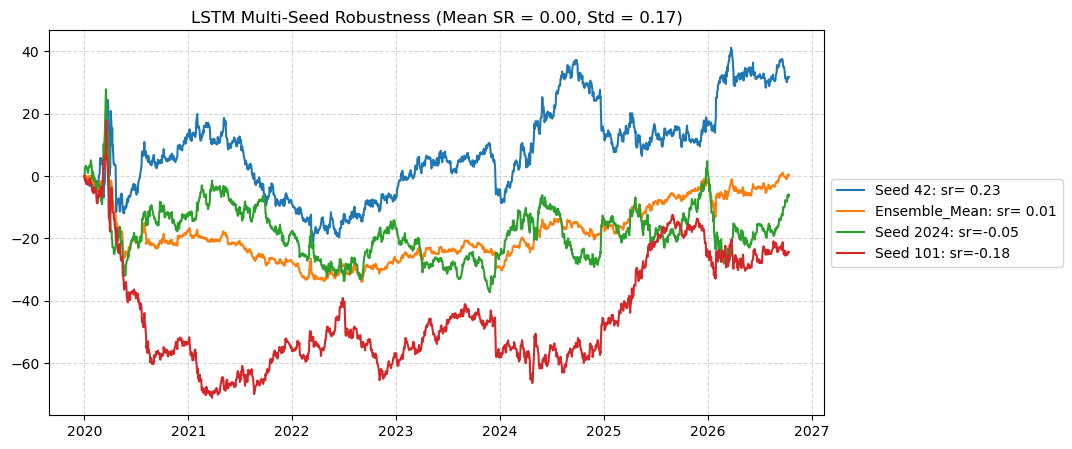

In [11]:
# Run walk-forward backtest across random seeds
seeds = [42, 101, 2024]
seed_pnls = {}

for s in seeds:
    print(f"Running walk-forward backtest for Seed {s}...")
    est_seed = make_pipeline(
        StandardScaler(with_mean=False),
        PyTorchLSTMRegressor(
            hidden_size=16,
            lookback=60,
            dropout=0.2,
            lr=1e-3,
            epochs=15,
            batch_size=64,
            loss_type="huber",
            val_split=0.15,
            patience=5,
            random_state=s,
            verbose=False,
        ),
        MeanVariance(),
    )
    bt_seed = Backtester(
        estimator=est_seed,
        max_train_size=756,
        test_size=21,
        start_date="2020-01-01",
        name=f"Seed {s}",
    )
    seed_pnls[f"Seed {s}"] = bt_seed.train(X, y, ret_aligned)

seed_df = pd.DataFrame(seed_pnls)
seed_srs = [sharpe_ratio(seed_df[col]) for col in seed_df.columns]

print(f"Mean Sharpe across seeds: {np.mean(seed_srs):.2f} +/- {np.std(seed_srs):.2f}")
print(f"Min Sharpe: {np.min(seed_srs):.2f}, Max Sharpe: {np.max(seed_srs):.2f}")

# Plot seed distribution
line(
    seed_df.assign(Ensemble_Mean=seed_df.mean(axis=1)),
    cumsum=True,
    title=f"LSTM Multi-Seed Robustness (Mean SR = {np.mean(seed_srs):.2f}, Std = {np.std(seed_srs):.2f})",
    figsize=(10, 5),
)

## 9. Integration Handoff for Teammate (Tomàs's Deliverables)
This section marks the exact interface points where Tomàs will integrate the remaining project components:

```
+---------------------------------------------------------------------------------------------------+
| PIPELINE HANDOFF INTERFACES:                                                                      |
| 1. Risk & Transaction Cost Modeling:                                                              |
|    - Module: skfin.backtesting_with_cost.BacktesterWithCost                                       |
|    - Inputs: h_lstm (from Section 6), ret_aligned, vol_liquidity_factor                          |
|    - Outputs: Gross PnL, Net PnL, Impact Cost breakdown                                          |
|                                                                                                   |
| 2. Hyperparameter Tuning of Baselines:                                                            |
|    - RidgeCV: Tuning alpha over [1e-2, 1e-1, 1, 10, 100, 1000]                                  |
|    - MultiLGBMRegressor: Tuning min_child_samples, learning_rate, and max_depth                   |
|                                                                                                   |
| 3. Statistical Validation:                                                                        |
|    - Lo (2002) Sharpe ratio confidence intervals with non-IID serial correlation corrections     |
|    - Off-the-top asset drop sensitivity tests                                                     |
+---------------------------------------------------------------------------------------------------+
```

### 9.1 Transaction Cost Modeling Interface Placeholder
```python
# from skfin.backtesting_with_cost import BacktesterWithCost, compute_pnl_components
#
# # Teammate plugs in the calibrated liquidity cost factors:
# # vol_liquidity_factor = compute_liquidity_factor(...)
# # bt_cost = BacktesterWithCost(estimator=lstm_pipeline, vol_liquidity_factor=vol_liquidity_factor)
# # net_results = bt_cost.train(X, y, ret_aligned)
```

### 9.2 Tuned Baselines Interface Placeholder
```python
# from skfin.estimators import RidgeCV, MultiLGBMRegressor
#
# # Teammate plugs in tuned RidgeCV and LightGBM models:
# # tuned_ridge = make_pipeline(StandardScaler(with_mean=False), RidgeCV(alphas=[0.1, 1, 10, 100]), MeanVariance())
# # tuned_lgbm  = make_pipeline(MultiLGBMRegressor(n_estimators=30, learning_rate=0.05), MeanVariance())
```

### 9.3 Statistical Validation Interface Placeholder
```python
# # Teammate computes Lo (2002) confidence intervals:
# # lo_ci_lstm = compute_lo_confidence_interval(pnl_lstm)
# # lo_ci_ridge = compute_lo_confidence_interval(pnl_ridge)
```
